<a href="https://colab.research.google.com/github/sebassanchez5680-tech/Prueba/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Sebastian Miguel Sanchez Salas
*   Matrícula: 271757

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [2]:
# 1. Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Configuración visual
sns.set_theme(style="whitegrid")

# 2. Cargar el archivo advertising.csv
df = pd.read_csv('advertising.csv')

# 3. Mostrar las primeras filas del dataframe
print("=== Primeras 5 filas del DataFrame ===")
print(df.head(5))
# 4. Describir estadísticamente las variables (incluyendo la mediana)
print("\n=== Descripción Estadística de las Variables ===")
desc = df.describe().T
print(desc)

=== Primeras 5 filas del DataFrame ===
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

=== Descripción Estadística de las Variables ===
           count      mean        std  min     25%     50%      75%    max
TV         200.0  147.0425  85.854236  0.7  74.375  149.75  218.825  296.4
Radio      200.0   23.2640  14.846809  0.0   9.975   22.90   36.525   49.6
Newspaper  200.0   30.5540  21.778621  0.3  12.750   25.75   45.100  114.0
Sales      200.0   15.1305   5.283892  1.6  11.000   16.00   19.050   27.0


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

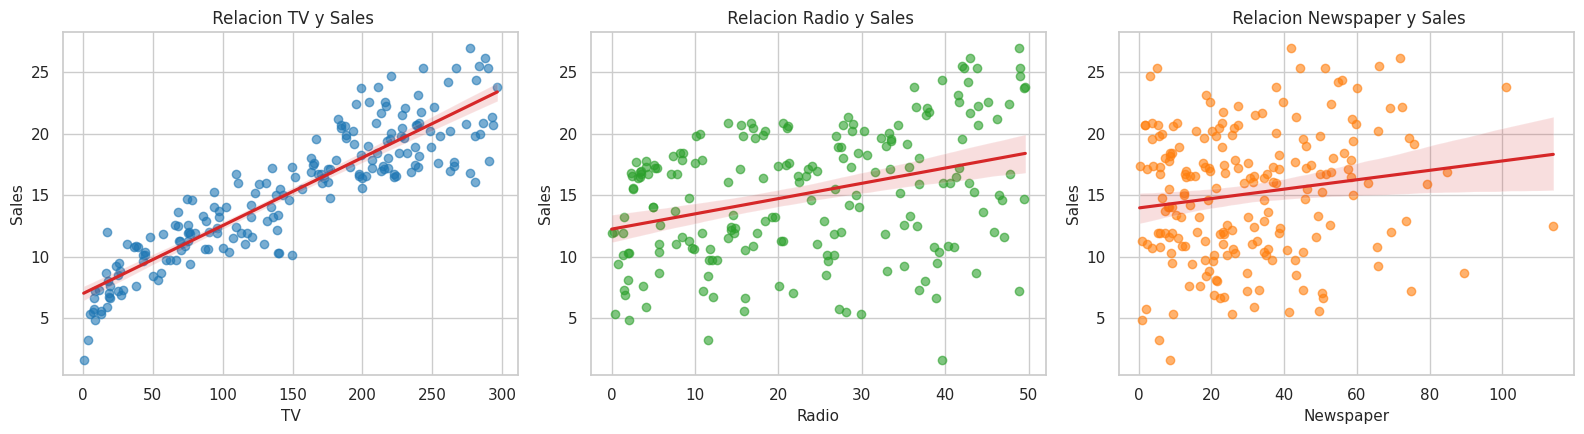

In [3]:
# Gráficos de dispersión
# 2.1 Gráficos de dispersión con línea de regresión (regplot)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
variables = ['TV', 'Radio', 'Newspaper']
color = ['#1f77b4', '#2ca02c', '#ff7f0e']

for ax, var, col in zip(axes, variables, color):
    sns.regplot(data=df, x=var, y='Sales', ax=ax, color=col,scatter_kws={'alpha': 0.6}, line_kws={'color': '#d62728'})
    ax.set_title(f' Relacion {var} y Sales')
    ax.set_xlabel(f'{var}', fontsize=11)
    ax.set_ylabel('Sales', fontsize=11)

plt.tight_layout()
plt.show()

1. TV vs Sales: Se observa una relacion casi completamente lineal positiva. A medida que incrementa la inversion publicitaria en television, las ventas aumentan de igual forma.

2. Radio vs Sales: Presenta una relacion lineal positiva no tan marcada. Existe una tendencia ascendente clara, aunque los puntos muestran una mayor dispersion.

3. Newspaper vs Sales: Muestra una relacion lineal muy debil o practicamente nula. Los puntos se encuentran altamente dispersos sin seguir un patron claro.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

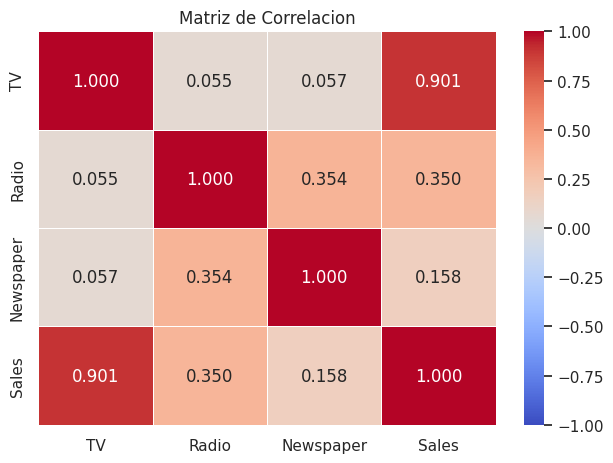

In [4]:
# Correlación y heatmap
corr_matrix = df.corr() #calcula la matriz de correlacion
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlacion')
plt.tight_layout()
plt.show()

La variable TV tiene la mayor correlacion con Sales, ya que alcanza un coeficiente de correlacion de Pearson de r = 0.9012, mientras que le sigue por lejos la Radio (r = 0.3496) y ultima Newspaper (r = 0.1580).

No hay ninguna correlacion alta entre los predictores. Las correlaciones entre TV y Radio (r = 0.0548) y TV y Newspaper (r = 0.0566) son casi nulas. Mientras que entre Radio y Newspaper es un poco mas alta (r = 0.3541).

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

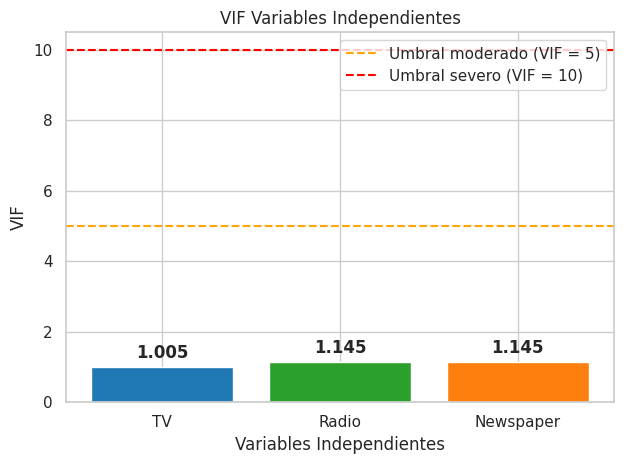

In [5]:
# Parte 3: Cálculo del VIF y diagrama de barras
v = df[['TV', 'Radio', 'Newspaper']]
#calculo del variance inflation factor
vif_df = pd.DataFrame({'Variable': v.columns,'VIF': [variance_inflation_factor(v.values, i) for i in range(v.shape[1])]})

bars = plt.bar(vif_df['Variable'], vif_df['VIF'], color=['#1f77b4', '#2ca02c', '#ff7f0e'])
plt.axhline(5, color='orange', linestyle='--', label='Umbral moderado (VIF = 5)') #Lineas limite
plt.axhline(10, color='red', linestyle='--', label='Umbral severo (VIF = 10)')
plt.title('VIF Variables Independientes')
plt.xlabel('Variables Independientes')
plt.ylabel('VIF')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.25, f'{yval:.3f}', ha='center', fontweight='bold') #valor arriba de la barra

plt.legend()
plt.tight_layout()
plt.show()

Ninguna variable alcanza a superar el 10 y 5 de valor de VIF

El que los valores no llegaran a ser superiores a 5 indica que no existe multicolinealidad entre las variables independientes. Por lo tanto, las estimaciones de los coeficientes de regresión son estables y sus errores estandar no están inflados.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [6]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
X_full = df[['TV', 'Radio', 'Newspaper']] #var ind
y = df['Sales']

modelo = LinearRegression()
modelo.fit(X_full, y)

print(f"(β0): {modelo.intercept_:.6f}")
for var, coef in zip(X_full.columns, modelo.coef_):
    print(f"Coeficiente {var}: {coef:.6f}")

(β0): 4.625124
Coeficiente TV: 0.054446
Coeficiente Radio: 0.107001
Coeficiente Newspaper: 0.000336


$\beta_0$ = 4.6251: Es el nivel base estimado de ventas (4.6251 unidades) cuando la inversion publicitaria en TV, Radio y Newspaper es igual a cero.

Coeficiente de TV = 0.054446: Por cada unidad adicional invertida en publicidad TV, las ventas aumentan en 0.0544 unidades.

Coeficiente de Radio = 0.107001: Por cada unidad adicional invertida en Radio, las ventas se incrementan en 0.1070 unidades.

Coeficiente de Newspaper  = 0.000336: Un incremento de una unidad en Newspaper se asocia con un cambio practicamente nulo de 0.0003 unidades en las ventas.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

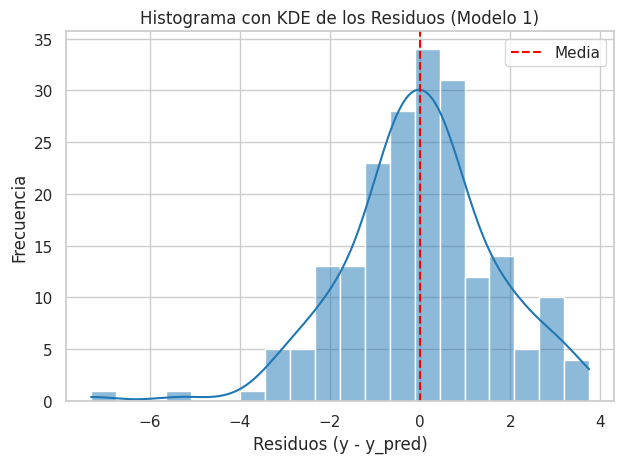

In [7]:
#Normalidad de los residuos
y_pred_1 = modelo.predict(X_full)
residuos_1 = y - y_pred_1 #valor real menos la prediccion

sns.histplot(residuos_1, kde=True, color='#1f77b4', bins=20)
plt.axvline(0, color='red', linestyle='--', label='Media')
plt.title('Histograma con KDE de los Residuos (Modelo 1)')
plt.xlabel('Residuos (y - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

Si los residuos parecen tender a distribuirse como una distribucion normal, como se puede apreciar en la linea azul en la cual parece que cada barra se trata de ajustar.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

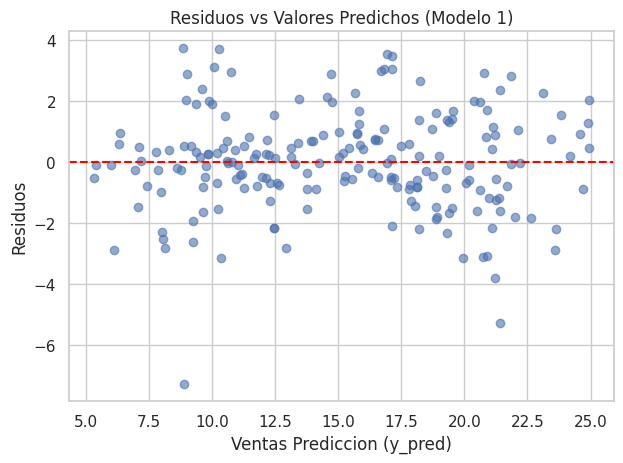

In [24]:
# Homocedasticidad
plt.scatter(y_pred_1, residuos_1, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuos vs Valores Predichos (Modelo 1)')
plt.xlabel('Ventas Prediccion (y_pred)')
plt.ylabel('Residuos')
plt.tight_layout()
plt.show()

La dispersion de la informacion se centra bastante en el 0, aunque en los calores extremos de y-pred se tienen algunos valores que se salen del patron

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

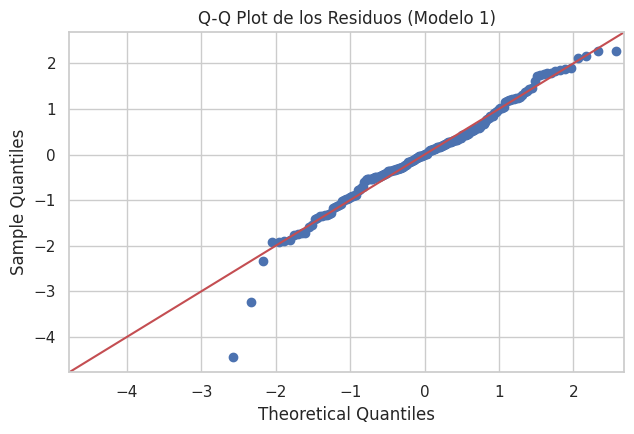

In [9]:
#Q-Q Plot
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sm.qqplot(residuos_1, line='45', fit=True, ax=ax)
ax.set_title('Q-Q Plot de los Residuos (Modelo 1)')
plt.tight_layout()
plt.show()

Podemos ver que los puntos ubicados entre -2 y 2 se ajustan muy bien con la recta siguiendo un comportamiento normal, sin embargo fuera de esos limites existe una dispersion de los datos, indicandonos que existen colas pesadas.


### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [10]:
#Evaluación del Modelo

mse_1 = mean_squared_error(y, y_pred_1)
rmse_1 = np.sqrt(mse_1)
r2_1 = r2_score(y, y_pred_1)

print(f"MSE (Error Cuadratico Medio): {mse_1:.6f}")
print(f"RMSE (Raiz del Error Cuadratico Medio): {rmse_1:.6f}")
print(f"R² (Coeficiente de Determinación): {r2_1:.6f}")

MSE (Error Cuadrático Medio): 2.706006
RMSE (Raíz del Error Cuadrático Medio): 1.644994
R² (Coeficiente de Determinación): 0.902591


 El coeficiente $R^2$ = 0.9026 nos dice que el 90.26\% de la variabilidad total de las ventas es explicada por el modelo de regresion lineal multiple. Ademas, el $\text{RMSE} = 1.6450$ señala que las predicciones del modelo se desvian en promedio $\pm 1.645$ unidades respecto a las ventas reales.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

/tmp/ipykernel_784/59716503.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


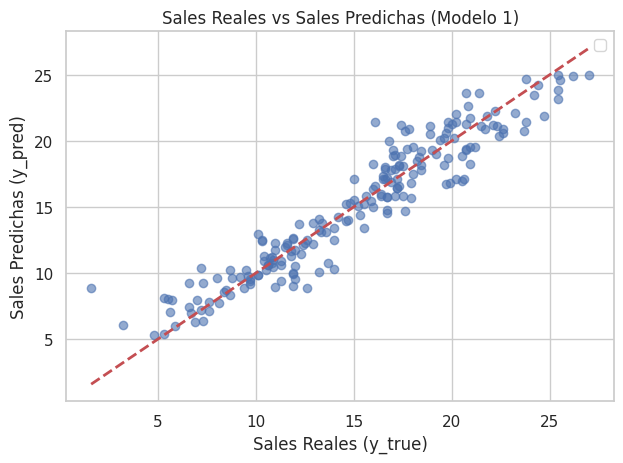

In [28]:
#Visualización de las Predicciones

plt.scatter(y, y_pred_1, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.title('Sales Reales vs Sales Predichas (Modelo 1)')
plt.xlabel('Sales Reales (y_true)')
plt.ylabel('Sales Predichas (y_pred)')
plt.legend()
plt.tight_layout()
plt.show()

Los puntos se agrupan de manera compacta alrededor de la linea diagonal roja de ajuste perfecto ($y = \hat{y}$) a lo largo de todo el rango de ventas. demostrando la alta precision predictiva del modelo ($R^2 = 0.9026$) ademas de identificar que las mayores discrepancias ocurren unicamente en un par de puntos en las colas.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [12]:
#P-values

X_full_sm = sm.add_constant(X_full)
modelo_ols_1 = sm.OLS(y, X_full_sm).fit()
print(modelo_ols_1.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        14:37:29   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

los unicos valores menores a 0.05 es TV y Radio. Por el contrario, Newspaper tiene un valor $p = 0.954$, muy superior al umbral de significancia.
Por lo que se concluye que TV y Radio son estadisticamente significantes y aportan informacion real para predecir las ventas, mientras que Newspaper no tiene un impacto estadisticamente significativo sobre las ventas cuando TV y Radio ya están presentes en el modelo.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**ninguna variable presentó multicolinealidad**

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

 Como vimos en los ejercicios pasados Newspaper presento el VIF mas alto, ausencia de relación lineal con Sales y una significancia practicamente nula. Por ello, se procede a construir y evaluar el modelo eliminando Newspaper y conservando solo las variables TV y Radio.

In [13]:
# 5.1 Entrenamiento del modelo eliminando Newspaper (usando TV y Radio)
X_red = df[['TV', 'Radio']]
y = df['Sales']

modelo_2 = LinearRegression()
modelo_2.fit(X_red, y)

print(f"Intercepto (β0): {modelo_2.intercept_:.6f}")
for var, coef in zip(X_red.columns, modelo_2.coef_):
    print(f"Coeficiente {var}: {coef:.6f}")

Intercepto (β0): 4.630879
Coeficiente TV: 0.054449
Coeficiente Radio: 0.107175


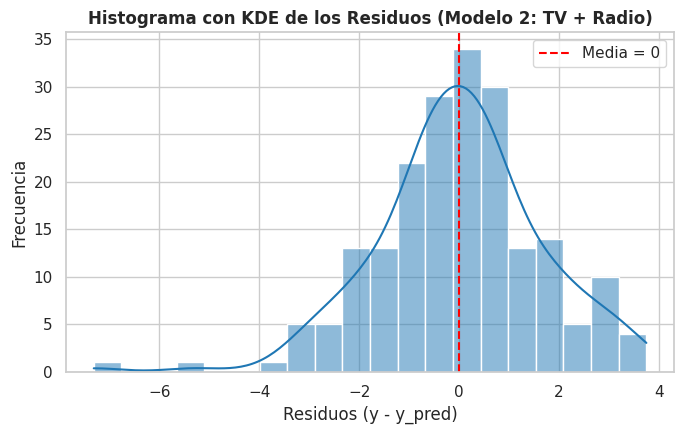

In [14]:
# 5.2 Cálculo de residuos e histograma con KDE (Modelo 2)
y_pred_2 = modelo_2.predict(X_red)
residuos_2 = y - y_pred_2

plt.figure(figsize=(7, 4.5))
sns.histplot(residuos_2, kde=True, color='#1f77b4', bins=20)
plt.axvline(0, color='red', linestyle='--', label='Media = 0')
plt.title('Histograma con KDE de los Residuos (Modelo 2: TV + Radio)', fontsize=12, fontweight='bold')
plt.xlabel('Residuos (y - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

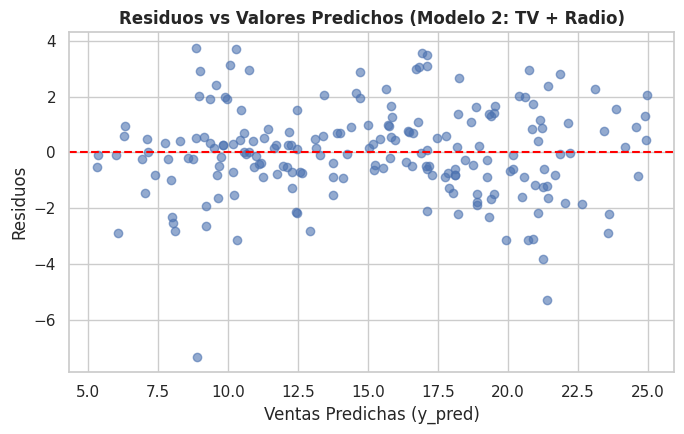

In [21]:
# 5.3 Residuos contra valores predichos (Modelo 2)
plt.figure(figsize=(7, 4.5))
plt.scatter(y_pred_2, residuos_2, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuos vs Valores Predichos (Modelo 2: TV + Radio)', fontsize=12, fontweight='bold')
plt.xlabel('Ventas Predichas (y_pred)')
plt.ylabel('Residuos')
plt.tight_layout()
plt.show()

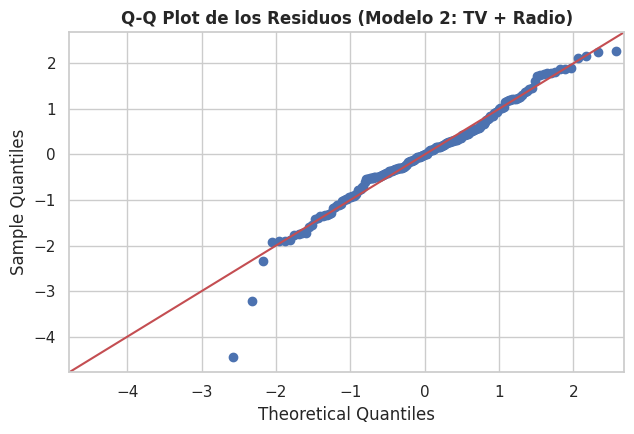

In [16]:
# 5.4 Q-Q Plot de los residuos (Modelo 2)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sm.qqplot(residuos_2, line='45', fit=True, ax=ax)
ax.set_title('Q-Q Plot de los Residuos (Modelo 2: TV + Radio)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# 5.5 Métricas de evaluación del Modelo 2 (MSE, RMSE, R2)
mse_2 = mean_squared_error(y, y_pred_2)
rmse_2 = np.sqrt(mse_2)
r2_2 = r2_score(y, y_pred_2)

print(f"MSE (Error Cuadrático Medio): {mse_2:.6f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse_2:.6f}")
print(f"R² (Coeficiente de Determinación): {r2_2:.6f}")

MSE (Error Cuadrático Medio): 2.706053
RMSE (Raíz del Error Cuadrático Medio): 1.645008
R² (Coeficiente de Determinación): 0.902590


/tmp/ipykernel_784/2156054811.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


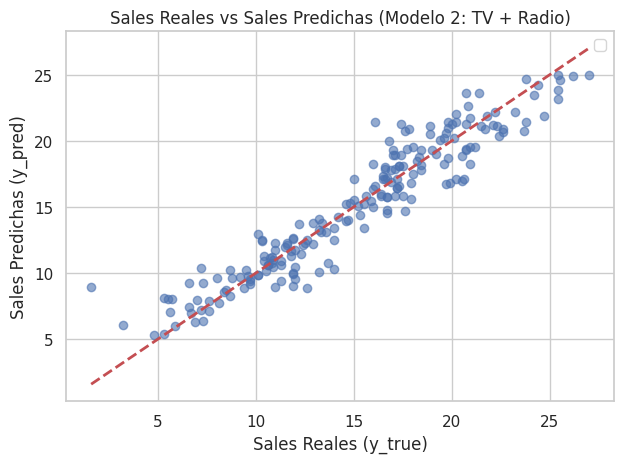

In [27]:
# 5.6 Gráfico de Sales reales vs Sales predichas (Modelo 2)
plt.scatter(y, y_pred_2, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.title('Sales Reales vs Sales Predichas (Modelo 2: TV + Radio)')
plt.xlabel('Sales Reales (y_true)')
plt.ylabel('Sales Predichas (y_pred)')
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# 5.7 Ajuste del Modelo 2 usando statsmodels
X_red_sm = sm.add_constant(X_red)
modelo_ols_2 = sm.OLS(y, X_red_sm).fit()
print(modelo_ols_2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        14:37:30   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

El Modelo 2 con el que no mas usamos 2 variables es el mejor modelo. Ya que explica exactamente el mismo porcentaje de varianza de las ventas ($90.26\%$) con menor complejidad, logra un mayor $R^2$ Ajustado ($0.902$ vs $0.901$), presenta menores valores de AIC ($772.7$) y BIC ($782.6$), eleva la significancia global del modelo ($F = 912.7$) y sin el ruido de una variable estadisticamente irrelevante (Newspaper).

En el impacto total sobre la variabilidad de las ventas, el atributo mas influyente es TV, ya que posee la correlacion mas alta con las ventas ($r = 0.9012$), el mayor estadistico $t$ ($t = 39.726$ frente a $13.522$ de Radio) y el mayor coeficiente estandarizado ($\beta_{\text{TV}} = 0.8847$ ), explicando la mayor parte del volumen de ventas.